In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import arabic_reshaper
from bidi.algorithm import get_display

In [2]:
products_path = Path("digikala-products.csv")
comments_path = Path("digikala-comments.csv")

for file in [products_path, comments_path]:
    print(f"File: {file.name}")
    print(f"Exists: {file.exists()}")

    if file.exists():
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"Size: {size_mb:.2f} MB")

    print("-" * 40)

File: digikala-products.csv
Exists: True
Size: 246.75 MB
----------------------------------------
File: digikala-comments.csv
Exists: True
Size: 1219.30 MB
----------------------------------------


In [3]:
df_products = pd.read_csv(products_path, low_memory=False, dtype={"Category2": "string"})
df_comments = pd.read_csv(comments_path, low_memory=False)

print("Products shape:", df_products.shape)
print("Comments shape:", df_comments.shape)

display(df_products.head())
display(df_comments.head())

Products shape: (1283496, 12)
Comments shape: (6156289, 15)


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,<NA>,متفرقه,634800,سلامت ساز راد,False,0,beauty
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,<NA>,متفرقه,818800,مهر افزون,False,0,beauty
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,<NA>,متفرقه,920000,یانگوم,False,0,beauty
3,1912926,استند ابسلانگ مدل S01,78,25,آبسلانگ,<NA>,متفرقه,1100000,بهراد طب بیدار,False,0,beauty
4,6335462,آبسلانگ نوری تسلامد مدل All-in-One,84,25,آبسلانگ,<NA>,تسلا مد,1530000,دیجی‌کالا,False,0,beauty


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN


In [4]:
print(df_products.isnull().sum())

id                           0
title_fa                     0
Rate                         0
Rate_cnt                     0
Category1                    0
Category2               210108
Brand                        0
Price                        0
Seller                     223
Is_Fake                      0
min_price_last_month         0
sub_category                 0
dtype: int64


In [5]:
print(df_comments.isnull().sum())

id                             0
title                    2865062
body                         637
created_at                     0
rate                           0
recommendation_status     894426
is_buyer                       0
product_id                     0
advantages               5448084
disadvantages            5744017
likes                          0
dislikes                       0
seller_title              302181
seller_code               302181
true_to_size_rate        6065516
dtype: int64


In [6]:
# Products
print("Products:")
print("Duplicate rows:",
      df_products.duplicated().sum())

print("Duplicate IDs:",
      df_products["id"].duplicated().sum())


# Comments
print("\nComments:")
print("Duplicate rows:",
      df_comments.duplicated().sum())

print("Duplicate IDs:",
      df_comments["id"].duplicated().sum())

Products:
Duplicate rows: 323129
Duplicate IDs: 335144

Comments:
Duplicate rows: 1318
Duplicate IDs: 3229


In [7]:
for name, df in [
    ("Products", df_products),
    ("Comments", df_comments)
]:

    duplicated_mask = df["id"].duplicated(keep=False)

    print(f"\n{name}")
    print("Unique duplicated IDs:", df.loc[duplicated_mask, "id"].nunique())

    print("Total rows involved in duplicates:", duplicated_mask.sum())

    print("\nMost repeated IDs:")
    print(df.loc[duplicated_mask, "id"].value_counts().head(10))


Products
Unique duplicated IDs: 258718
Total rows involved in duplicates: 593862

Most repeated IDs:
id
2577295    11
2577200    10
2569919    10
2577471    10
6897398     9
4426409     9
6897295     9
4278054     9
2577503     9
2585276     9
Name: count, dtype: int64

Comments
Unique duplicated IDs: 3226
Total rows involved in duplicates: 6455

Most repeated IDs:
id
54490233    3
53766536    3
53973644    3
51540298    2
53570473    2
54446387    2
52238912    2
54710748    2
53672599    2
9897229     2
Name: count, dtype: int64


In [8]:
product_duplicates = df_products[df_products["id"].duplicated(keep=False)].sort_values("id")

display(
    product_duplicates[
        ["id", "title_fa", "Brand", "Price",
         "Seller", "Rate", "Rate_cnt"]
    ].head(20)
)

,id,title_fa,Brand,Price,Seller,Rate,Rate_cnt
344968,12298,ساعت مچی عقربه ای مردانه کاسیو جی شاک GA-110-1ADR,کاسیو,57312000,دیجی‌کالا,64,21
350656,12298,ساعت مچی عقربه ای مردانه کاسیو جی شاک GA-110-1ADR,کاسیو,70832000,دیجی‌کالا,64,21
1057440,19287,آلبوم موسیقی آتشی در نیستان اثر شهرام ناظری,چهار باغ,1200000,استریو تومبا,90,19
1057447,19287,آلبوم موسیقی آتشی در نیستان اثر شهرام ناظری,چهار باغ,1200000,استریو تومبا,90,19
1056734,22572,آلبوم موسیقی عشق است اثر ناصر عبداللهی و امیر ...,دارینوش,1000000,استریو تومبا,72,15
1056766,22572,آلبوم موسیقی عشق است اثر ناصر عبداللهی و امیر ...,دارینوش,1000000,استریو تومبا,72,15
350567,26147,ساعت مچی عقربه ای مردانه کاسیو کاسیو-GA-100A-9A,کاسیو,62444000,دیجی‌کالا,80,2
344702,26147,ساعت مچی عقربه ای مردانه کاسیو کاسیو-GA-100A-9A,کاسیو,52236000,دیجی‌کالا,80,2
320417,27925,ساعت مچی عقربه ای مردانه فستینا مدل F16600/5,فستینا,131000000,گالری مختاری نوا,0,0
352360,27925,ساعت مچی عقربه ای مردانه فستینا مدل F16600/5,فستینا,131000000,گالری مختاری نوا,0,0


In [9]:
comment_duplicates = df_comments[df_comments["id"].duplicated(keep=False)].sort_values("id")

display(
    comment_duplicates[
        ["id", "product_id", "title", "body",
         "rate", "recommendation_status"]
    ].head(20)
)

,id,product_id,title,body,rate,recommendation_status
1603315,1002211,65742,پیشنهاد,یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکن...,3.00,NaN
1603222,1002211,65742,پیشنهاد,یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکن...,3.00,NaN
1267069,1123478,156134,کتاب صوتی شازده کوچولو,یکی از مهمترین مزایای کتاب صوتی قابل استفاده ب...,0.00,NaN
1267067,1123478,156134,کتاب صوتی شازده کوچولو,یکی از مهمترین مزایای کتاب صوتی قابل استفاده ب...,0.00,NaN
593999,1153354,68722,کیفیت عالی اثر,تنها میتونم بگم این کتاب فوق العاده س.\r\nمن ب...,5.00,NaN
593895,1153354,68722,کیفیت عالی اثر,تنها میتونم بگم این کتاب فوق العاده س.\r\nمن ب...,5.00,NaN
1603314,1162097,65742,فوقلعلاده است!,این یکی از شیرین ترین داشتان هاییهکه خوندم، مث...,4.15,NaN
1603221,1162097,65742,فوقلعلاده است!,این یکی از شیرین ترین داشتان هاییهکه خوندم، مث...,4.15,NaN
930958,1186549,170863,بسیار,بسیار عالی بود. کیفیت صدا بسیار خوب بود.\r\nپس...,4.75,NaN
930873,1186549,170863,بسیار,بسیار عالی بود. کیفیت صدا بسیار خوب بود.\r\nپس...,4.75,NaN


In [10]:
def check_duplicate_differences(df, id_col):

    duplicated = df[df[id_col].duplicated(keep=False)]
    grouped = duplicated.groupby(id_col).nunique(dropna=False)

    differences = grouped.gt(1).sum()

    print("Number of duplicated IDs:",
          len(grouped))

    print("\nColumns with different values:")
    display(
        differences[differences > 0]
        .sort_values(ascending=False)
    )

    print("\nIDs with at least one conflicting column:",
        grouped.gt(1).any(axis=1).sum()
    )


print("PRODUCTS ANALYSIS")
check_duplicate_differences(df_products, "id")

print("\nCOMMENTS ANALYSIS")
check_duplicate_differences(df_comments, "id")

PRODUCTS ANALYSIS
Number of duplicated IDs: 258718

Columns with different values:


Price                   8254
Seller                  4036
Rate_cnt                3251
min_price_last_month    1458
sub_category             757
Rate                     646
title_fa                   6
Brand                      2
dtype: int64


IDs with at least one conflicting column: 11785

COMMENTS ANALYSIS
Number of duplicated IDs: 3226

Columns with different values:


likes                    1217
dislikes                  294
body                      241
seller_title              154
seller_code               147
recommendation_status     101
title                      85
rate                       79
advantages                 41
is_buyer                   22
disadvantages               6
true_to_size_rate           4
dtype: int64


IDs with at least one conflicting column: 1908


In [11]:
products_unique = df_products.drop_duplicates()
comments_unique = df_comments.drop_duplicates()

print("Products remaining duplicate IDs:",
      products_unique["id"].duplicated().sum())

print("Comments remaining duplicate IDs:",
      comments_unique["id"].duplicated().sum())

Products remaining duplicate IDs: 12015
Comments remaining duplicate IDs: 1911


In [12]:
product_stats = df_products.groupby("id").agg(
    rows=("id", "size"),
    price_count=("Price", "nunique"),
    seller_count=("Seller", "nunique"),
    title_count=("title_fa", "nunique"),
    brand_count=("Brand", "nunique")
)

conflict_ids = product_stats[
    (product_stats["price_count"] > 1) |
    (product_stats["seller_count"] > 1) |
    (product_stats["title_count"] > 1) |
    (product_stats["brand_count"] > 1)
].sort_values("rows", ascending=False).head(5).index

display(
    df_products[df_products["id"].isin(conflict_ids)]
    .sort_values(["id", "Price"])
)

,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
988755,117958,کرم نرم کننده سی گل مدل Hydra Beauty حجم 50 می...,84,429,مراقبت پوست,کرم مرطوب کننده و نرم کننده,سی گل,340000,بیوتی مهد,False,340000,beauty
989935,117958,کرم نرم کننده سی گل مدل Hydra Beauty حجم 50 می...,84,429,مراقبت پوست,کرم مرطوب کننده و نرم کننده,سی گل,340000,بیوتی مهد,False,340000,beauty
1001503,117958,کرم نرم کننده سی گل مدل Hydra Beauty حجم 50 می...,84,429,مراقبت پوست,کرم مرطوب کننده و نرم کننده,سی گل,340000,بیوتی مهد,False,340000,beauty
981660,117958,کرم نرم کننده سی گل مدل Hydra Beauty حجم 50 می...,84,429,مراقبت پوست,کرم مرطوب کننده و نرم کننده,سی گل,347000,فروشگاه مهردارو,False,340000,beauty
991636,117958,کرم نرم کننده سی گل مدل Hydra Beauty حجم 50 می...,84,429,مراقبت پوست,کرم مرطوب کننده و نرم کننده,سی گل,347000,فروشگاه مهردارو,False,340000,beauty
993955,117958,کرم نرم کننده سی گل مدل Hydra Beauty حجم 50 می...,84,429,مراقبت پوست,کرم مرطوب کننده و نرم کننده,سی گل,347000,فروشگاه مهردارو,False,340000,beauty
994552,117958,کرم نرم کننده سی گل مدل Hydra Beauty حجم 50 می...,84,429,مراقبت پوست,کرم مرطوب کننده و نرم کننده,سی گل,347000,فروشگاه مهردارو,False,340000,beauty
981751,4934880,وازلین وسیم مدل توت فرنگی حجم 100 میلی لیتر,88,50,مراقبت پوست,کرم مرطوب کننده و نرم کننده,متفرقه,340000,پدیدار آوا,False,0,beauty
991760,4934880,وازلین وسیم مدل توت فرنگی حجم 100 میلی لیتر,88,50,مراقبت پوست,کرم مرطوب کننده و نرم کننده,متفرقه,340000,پدیدار آوا,False,0,beauty
994018,4934880,وازلین وسیم مدل توت فرنگی حجم 100 میلی لیتر,88,50,مراقبت پوست,کرم مرطوب کننده و نرم کننده,متفرقه,340000,پدیدار آوا,False,0,beauty


In [13]:
comment_stats = df_comments.groupby("id").agg(
    rows=("id", "size"),
    body_count=("body", lambda x: x.nunique(dropna=False)),
    title_count=("title", lambda x: x.nunique(dropna=False)),
    rate_count=("rate", "nunique"),
    status_count=("recommendation_status",
                  lambda x: x.nunique(dropna=False))
)

conflict_ids = comment_stats[
    (comment_stats["body_count"] > 1) |
    (comment_stats["title_count"] > 1) |
    (comment_stats["rate_count"] > 1) |
    (comment_stats["status_count"] > 1)
].sort_values("rows", ascending=False).head(5).index

display(
    df_comments[df_comments["id"].isin(conflict_ids)][
        ["id", "product_id", "created_at", "title",
         "body", "rate", "recommendation_status",
         "likes", "dislikes"]
    ].sort_values("id")
)

,id,product_id,created_at,title,body,rate,recommendation_status,likes,dislikes
2532546,9182131,182941,21 خرداد 1399,کرم مرطوب‌کننده,در کل خوبه,4.0,recommended,0,0
4046087,9182131,182941,21 خرداد 1399,کرم مرطوب‌کننده,در کل خوبه,4.0,recommended,0,0
2696605,9196308,874372,22 خرداد 1399,قیمتش مناسب است,کیفیت خوبی دارد,4.0,recommended,0,0
989418,9196308,874372,22 خرداد 1399,NaN,کیفیت خوبی دارد,3.0,recommended,0,0
3996799,12862914,2670905,28 مهر 1399,کرم مرطوب کننده BBk,کرم خوبیه\r\nپیشنهاد میکنم,0.0,recommended,0,0
3561860,12862914,2670905,28 مهر 1399,کرم مرطوب کننده BBk,کرم خوبیه\r\nپیشنهاد میکنم,5.0,recommended,0,0
2831183,17111330,2952419,22 بهمن 1399,خوب نبود,حتی تو تخفیف هم ارزش خریدن نداره,0.0,not_recommended,4,0
2868980,17111330,2952419,22 بهمن 1399,خوب نبود,حتی تو تخفیف هم ارزش خریدن نداره,1.0,not_recommended,4,0
3965442,22662971,853680,14 تیر 1400,خوب بود,خوب بود,0.0,recommended,0,0
3715097,22662971,853680,14 تیر 1400,خوب بود,خوب بودخرید رو توصیه میکنم,5.0,recommended,0,0


In [14]:
# FINAL EDA - PART 1

# 1. Remove only completely identical rows
products_clean = df_products.drop_duplicates().copy()
comments_clean = df_comments.drop_duplicates().copy()

# 2. PRODUCT LEVEL ANALYSIS

products_clean["Price"] = pd.to_numeric(products_clean["Price"], errors="coerce")
products_clean["Rate"] = pd.to_numeric(products_clean["Rate"], errors="coerce")

# PRODUCT LEVEL ANALYSIS
# Aggregate price information per product
price_summary = products_clean.groupby("id")["Price"].agg(
    min_recorded_price="min",
    max_recorded_price="max",
    min_positive_price=lambda s: s[s > 0].min(),
    max_positive_price=lambda s: s[s > 0].max(),
    has_non_positive_offer=lambda s: s.le(0).any()
)

# Aggregate product-level information
product_level = products_clean.groupby("id").agg(
    Category1=("Category1", "first"),
    Rate=("Rate", "median"),
    seller_count=("Seller", "nunique"),
    offer_rows=("id", "size")
).join(price_summary)

# Use minimum positive price for product-level analysis
product_level["min_price"] = product_level["min_positive_price"]
product_level["max_price"] = product_level["max_positive_price"]

print("========== PRODUCT ANALYSIS ==========")

print("Rows after exact deduplication:",
      len(products_clean))

print("Unique products:",
      product_level.shape[0])

print("Products with multiple rows:",
      (product_level["offer_rows"] > 1).sum())

print("Products with multiple sellers:",
      (product_level["seller_count"] > 1).sum())

print("\nTop 10 Categories:")
print(product_level["Category1"].value_counts().head(10))

print("\nMinimum Positive Product Price Statistics:")
print(product_level["min_price"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.99]))

print("\nProduct Rating Statistics:")
print(product_level["Rate"].describe())

print("\nProducts with at least one non-positive offer:",
      product_level["has_non_positive_offer"].sum())

print("Products without any positive price:",
      product_level["min_price"].isna().sum())

print("Products with both positive and non-positive offers:",
      (product_level["has_non_positive_offer"] & product_level["min_price"].notna()).sum())

# 3. COMMENTS ANALYSIS

print("\n========== COMMENTS ANALYSIS ==========")

print("Rows after exact deduplication:",
      len(comments_clean))

print("Unique comment IDs:",
      comments_clean["id"].nunique())

print("\nRecommendation Status Distribution:")

status_count = comments_clean["recommendation_status"].value_counts(dropna=False)
status_percent = (comments_clean["recommendation_status"].value_counts(dropna=False, normalize=True) * 100).round(2)

print(pd.DataFrame({
    "count": status_count,
    "percentage": status_percent
}))

# Review text length
body_length = (comments_clean["body"].fillna("").astype(str).str.strip().str.len())

print("\nReview Body Length:")
print(body_length.describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.99]))

# Conflicting core fields for duplicate comment IDs
core_fields = [
    "product_id",
    "created_at",
    "title",
    "body",
    "rate",
    "recommendation_status"
]

comment_groups = comments_clean.groupby("id")

core_conflicts = (comment_groups[core_fields].nunique(dropna=False).gt(1))

print("\nComment IDs with conflicting core fields:",
      core_conflicts.any(axis=1).sum())

print("\nConflicts by column:")
print(core_conflicts.sum().sort_values(ascending=False))

# 4. PRODUCT-COMMENT RELATIONSHIP

print("\n========== RELATIONSHIP ANALYSIS ==========")

product_ids = set(products_clean["id"].dropna().unique())

comment_product_ids = set(
    comments_clean["product_id"].dropna().unique()
)

matched_rows = comments_clean["product_id"].isin(
    product_ids
)

matched_ids = product_ids.intersection(
    comment_product_ids
)

unmatched_ids = comment_product_ids - product_ids

print("Unique products:", len(product_ids))

print("Unique products with comments:",
      len(matched_ids))

print("Comment product IDs not found in products:",
      len(unmatched_ids))

print("Matched comment rows:",
      matched_rows.sum())

print("Unmatched comment rows:",
      (~matched_rows).sum())

print("Comment matching percentage:",
      round(matched_rows.mean() * 100, 2), "%")


========== PRODUCT ANALYSIS ==========
Rows after exact deduplication: 960367
Unique products: 948352
Products with multiple rows: 11785
Products with multiple sellers: 3994

Top 10 Categories:
Category1
لباس زنانه                77928
اکسسوری زنانه             57514
لباس مردانه               55970
اکسسوری زنانه و مردانه    52644
اسباب بازی                42645
دخترانه                   35260
زیورآلات طلا زنانه        32903
اکسسوری مردانه            32337
کتاب چاپی غیر فارسی       31792
دفتر و کاغذ و مقوا        30065
Name: count, dtype: int64

Minimum Positive Product Price Statistics:
count    9.481960e+05
mean     9.143214e+06
std      5.187056e+07
min      2.000000e+04
25%      7.400000e+05
50%      1.700000e+06
75%      4.580000e+06
90%      1.550000e+07
99%      1.206000e+08
max      8.499990e+09
Name: min_price, dtype: float64

Product Rating Statistics:
count    948352.00000
mean         30.41301
std          40.02431
min           0.00000
25%           0.00000
50%           0.

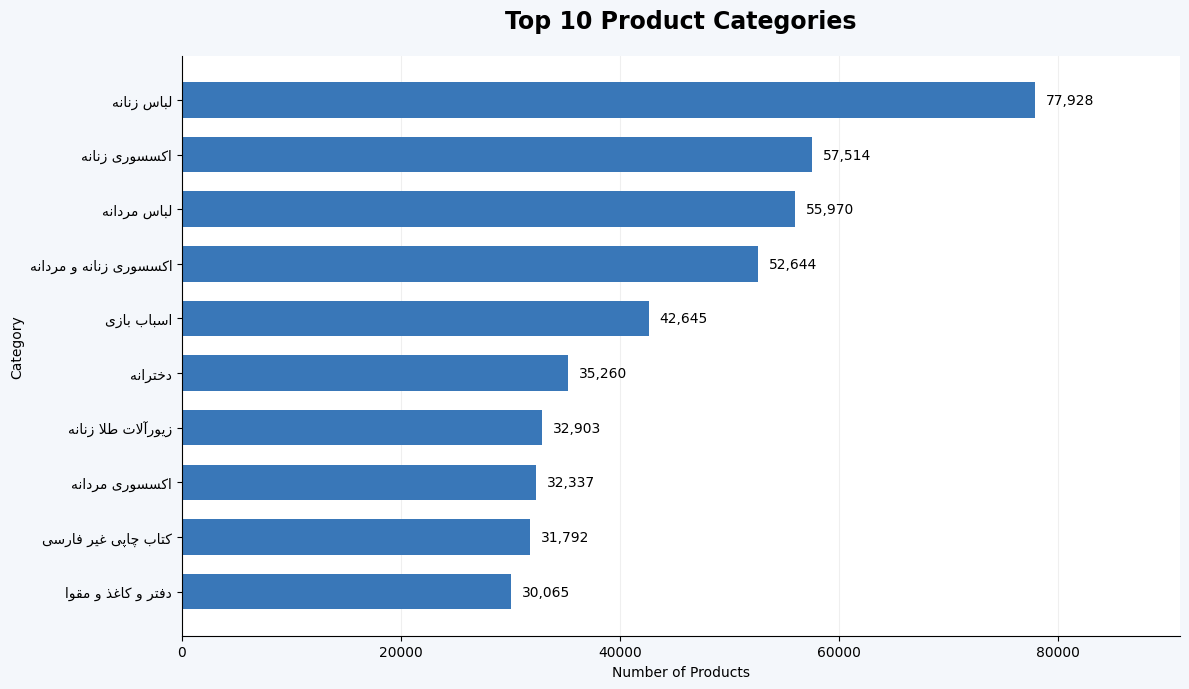

In [15]:
def fix_persian(text):
    return get_display(arabic_reshaper.reshape(str(text)))

top_categories = (product_level["Category1"].value_counts().head(10).sort_values())

labels = [fix_persian(x) for x in top_categories.index]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(labels, top_categories.values, color="#3977B8", height=0.65)

ax.set_title("Top 10 Product Categories", fontsize=17, fontweight="bold", pad=20)
ax.set_xlabel("Number of Products")
ax.set_ylabel("Category")

# Correct number formatting
for bar, value in zip(bars, top_categories.values):
    ax.text(bar.get_width() + 1000, bar.get_y() + bar.get_height() / 2, f"{value:,.0f}", va="center", fontsize=10)

ax.set_xlim(0, top_categories.max() * 1.17)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.patch.set_facecolor("#F4F7FB")
ax.set_facecolor("white")

plt.tight_layout()
plt.savefig("top10_categories.png", dpi=300, bbox_inches="tight")
plt.show()


In [16]:
# Visualization Style

plt.rcParams.update({
    "font.family": "Tahoma",
    "font.size": 10,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.unicode_minus": False
})

BG_COLOR = "#F3F6FA"
TEXT_COLOR = "#243247"
GRID_COLOR = "#E7EDF4"

def style_chart(ax, title, xlabel, ylabel):

    ax.set_title(title, color=TEXT_COLOR, pad=16)
    ax.set_xlabel(xlabel, labelpad=10)
    ax.set_ylabel(ylabel, labelpad=10)
    ax.set_facecolor("white")
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.9)
    ax.set_axisbelow(True)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_color("#DCE3EC")
    ax.spines["bottom"].set_color("#DCE3EC")


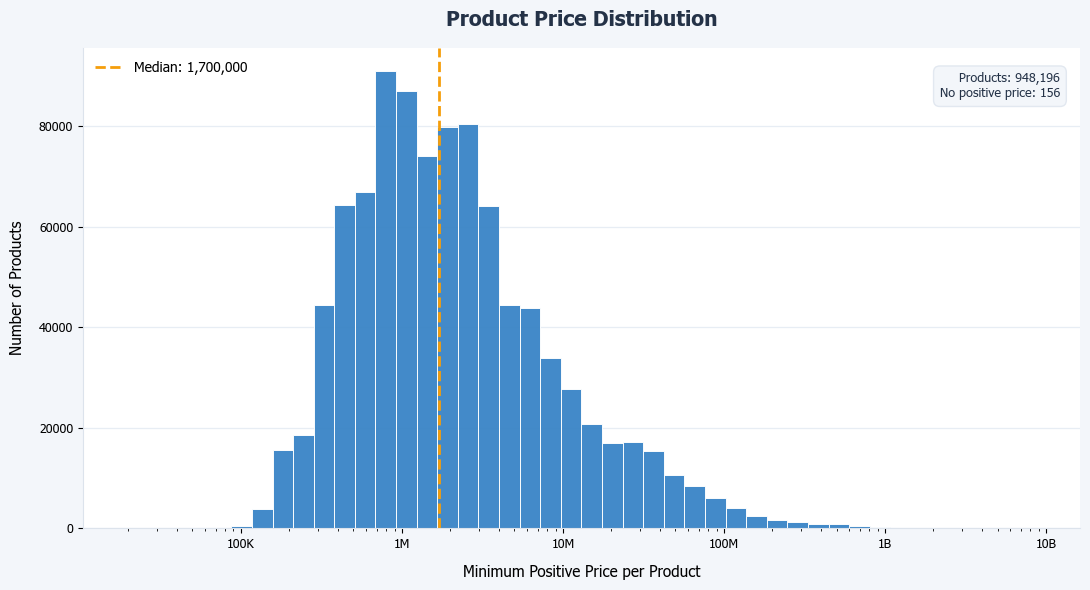

In [21]:
# 2. PRICE DISTRIBUTION
# Use the same price definition as product-level analysis
prices = product_level["min_price"].dropna()
no_positive_price = product_level["min_price"].isna().sum()

# Logarithmic bins
bins = np.geomspace(prices.min(),prices.max(),45)

fig, ax = plt.subplots(figsize=(11, 6))

fig.patch.set_facecolor(BG_COLOR)

ax.hist(prices, bins=bins, color="#3984C6", edgecolor="white", linewidth=0.7, alpha=0.95)
ax.set_xscale("log")

style_chart(ax, "Product Price Distribution", "Minimum Positive Price per Product", "Number of Products")

# Format price ticks
def format_price(x, pos):
    if x >= 1e9:
        return f"{x/1e9:g}B"
    elif x >= 1e6:
        return f"{x/1e6:g}M"
    elif x >= 1e3:
        return f"{x/1e3:g}K"
    return f"{x:g}"

ax.xaxis.set_major_locator(mticker.LogLocator(base=10, numticks=9))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(format_price))

# Median price
median_price = prices.median()

ax.axvline(median_price, color="#F59E0B", linestyle="--", linewidth=2, label=f"Median: {median_price:,.0f}")
ax.legend(frameon=False)
ax.text(0.98, 0.95, f"Products: {len(prices):,}\n" f"No positive price: {no_positive_price:,}", transform=ax.transAxes, ha="right", va="top", fontsize=9, color=TEXT_COLOR, 
        bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F3F6FA",
        edgecolor="#E2E8F0"
    )
)

plt.tight_layout()
plt.savefig("price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

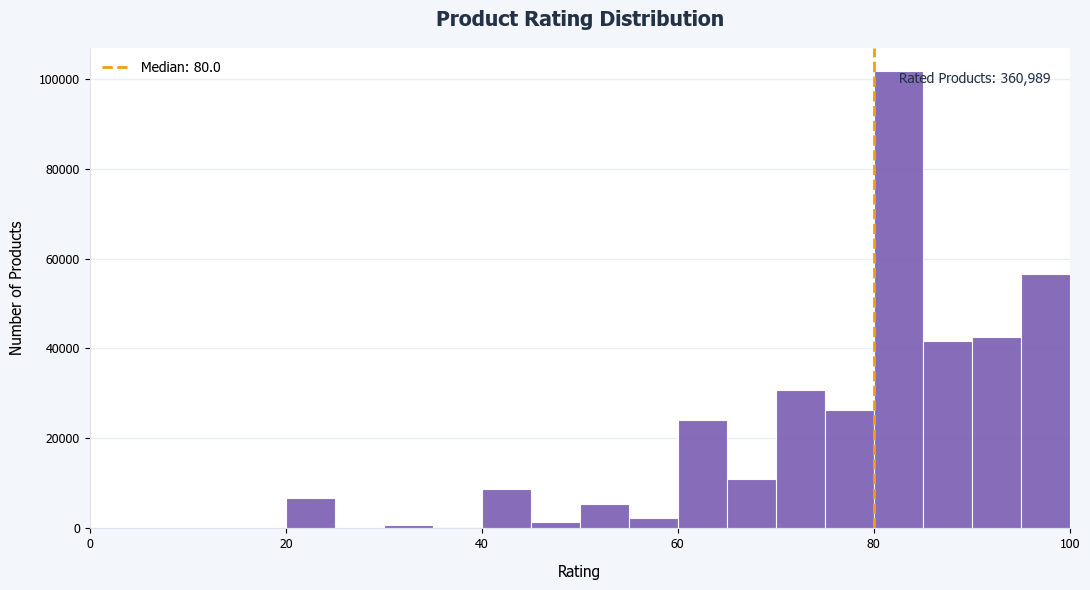

In [18]:
# 3. PRODUCT RATING DISTRIBUTION

rating_data = products_clean[["id", "Rate", "Rate_cnt"]].copy()
rating_data["Rate"] = pd.to_numeric(rating_data["Rate"], errors="coerce")
rating_data["Rate_cnt"] = pd.to_numeric(rating_data["Rate_cnt"], errors="coerce")

# Keep only rows with actual ratings
rating_data = rating_data[rating_data["Rate_cnt"] > 0]

# One representative rating per product
product_ratings = (rating_data.groupby("id")["Rate"].median().dropna())

# Keep valid rating range
product_ratings = product_ratings[product_ratings.between(0, 100)]

fig, ax = plt.subplots(figsize=(11, 6))

fig.patch.set_facecolor(BG_COLOR)

ax.hist(product_ratings, bins=np.arange(0, 105, 5), color="#8064B5", edgecolor="white", linewidth=0.8, alpha=0.95)

style_chart(ax, "Product Rating Distribution", "Rating", "Number of Products")

ax.set_xlim(0, 100)

# Median rating
median_rating = product_ratings.median()

ax.axvline(median_rating, color="#F59E0B", linestyle="--", linewidth=2, label=f"Median: {median_rating:.1f}")
ax.legend(frameon=False)
ax.text(0.98, 0.95, f"Rated Products: {len(product_ratings):,}", transform=ax.transAxes, ha="right", va="top", fontsize=10, color=TEXT_COLOR)

plt.tight_layout()
plt.savefig("rating_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

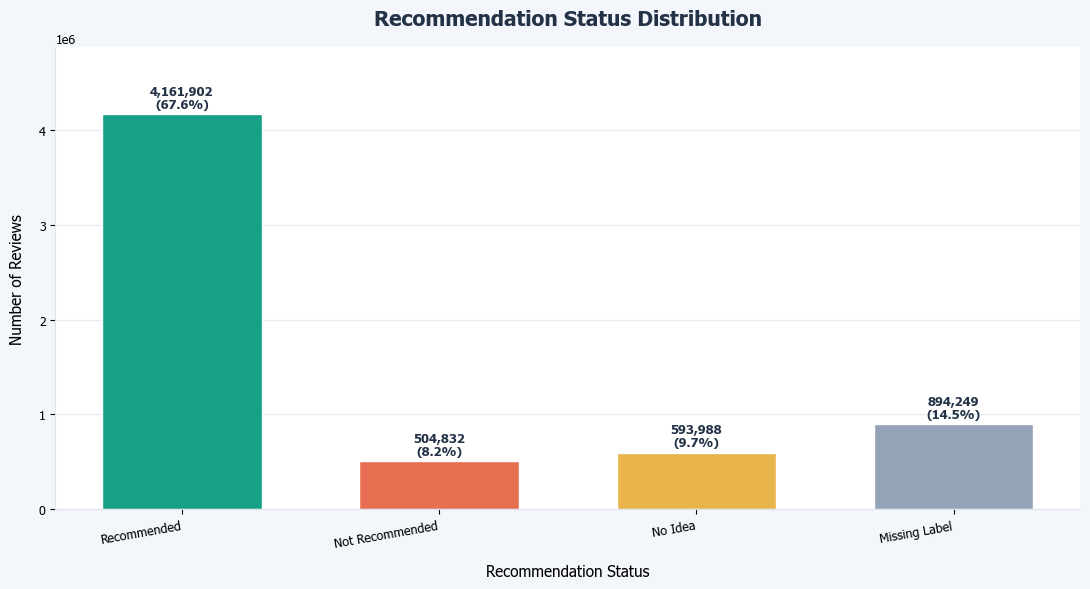

In [19]:
# 4. RECOMMENDATION STATUS DISTRIBUTION
status = comments_clean["recommendation_status"]

status_labels = ["Recommended", "Not Recommended", "No Idea", "Missing Label"]
status_counts = [status.eq("recommended").sum(), status.eq("not_recommended").sum(), status.eq("no_idea").sum(), status.isna().sum()]

colors = [
    "#16A085",
    "#E76F51",
    "#E9B44C",
    "#94A3B8"
]

fig, ax = plt.subplots(figsize=(11, 6))

fig.patch.set_facecolor(BG_COLOR)

bars = ax.bar(status_labels, status_counts, color=colors, width=0.62, edgecolor="white", linewidth=1)

style_chart(ax, "Recommendation Status Distribution", "Recommendation Status", "Number of Reviews")

total = len(comments_clean)

# Add count and percentage labels
for bar, count in zip(bars, status_counts):
    percentage = count / total * 100

    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + total * 0.008, f"{count:,}\n({percentage:.1f}%)", ha="center", va="bottom", fontsize=9, fontweight="bold", color=TEXT_COLOR)

ax.set_ylim(0, max(status_counts) * 1.17)

plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.savefig("recommendation_distribution.png", dpi=300, bbox_inches="tight")

plt.show()


In [20]:
rate_check = products_clean.groupby("id").agg(Rate=("Rate", "median"), Rate_cnt=("Rate_cnt", "max"))

print(pd.crosstab(
    rate_check["Rate"].eq(0),
    rate_check["Rate_cnt"].eq(0),
    rownames=["Rate is zero"],
    colnames=["Rate count is zero"]
))


Rate count is zero   False   True 
Rate is zero                      
False               360974       0
True                    15  587363
